In [2]:
import pandas as pd

df = pd.read_csv('mock_kpop_reactions.csv')
df = df.dropna(subset=['tokens']) # token이 빈행이면 .str.split에서 에러발생하는데 이를 막아주는 역할

ko = df[df['language'] == 'ko']
texts_ko = ko['tokens'].str.split().tolist()

In [3]:
from gensim.corpora.dictionary import Dictionary

dictionary = Dictionary(texts_ko)
print('#Number of initial unique words in documents:', len(dictionary))

dictionary.filter_extremes(keep_n = 2000, no_below=2, no_above=0.5)
print('#Number of unique words after removing rare and common words:', len(dictionary))

corpus = [dictionary.doc2bow(text) for text in texts_ko]
print('#Number of unique tokens: %d' % len(dictionary))
print('#Number of documents: %d' % len(corpus))

#Number of initial unique words in documents: 66
#Number of unique words after removing rare and common words: 15
#Number of unique tokens: 15
#Number of documents: 15


In [4]:
from gensim.models import LdaModel

num_topics = 10
passes = 5
%time model = LdaModel(corpus=corpus, id2word=dictionary,\
                       passes=passes, num_topics=num_topics, \
                       random_state=7)

CPU times: total: 78.1 ms
Wall time: 101 ms


In [5]:
model.print_topics(num_words=10)

[(0,
  '0.169*"소속사" + 0.169*"멤버" + 0.169*"팬" + 0.169*"콘서트" + 0.169*"노바" + 0.015*"뮤비" + 0.015*"라이브" + 0.015*"앨범" + 0.015*"무대" + 0.015*"신곡"'),
 (1,
  '0.314*"뮤비" + 0.314*"멤버" + 0.029*"라이브" + 0.029*"앨범" + 0.029*"소속사" + 0.029*"노바" + 0.029*"콘서트" + 0.029*"무대" + 0.029*"신곡" + 0.029*"신인"'),
 (2,
  '0.200*"소속사" + 0.200*"멤버" + 0.200*"라이브" + 0.200*"무대" + 0.018*"뮤비" + 0.018*"앨범" + 0.018*"노바" + 0.018*"콘서트" + 0.018*"팬" + 0.018*"신곡"'),
 (3,
  '0.169*"앨범" + 0.169*"제퍼" + 0.169*"데뷔" + 0.169*"그룹" + 0.169*"신인" + 0.015*"라이브" + 0.015*"멤버" + 0.015*"뮤비" + 0.015*"무대" + 0.015*"노바"'),
 (4,
  '0.314*"노바" + 0.314*"무대" + 0.029*"멤버" + 0.029*"라이브" + 0.029*"뮤비" + 0.029*"앨범" + 0.029*"소속사" + 0.029*"콘서트" + 0.029*"팬" + 0.029*"루믹"'),
 (5,
  '0.440*"라이브" + 0.040*"멤버" + 0.040*"소속사" + 0.040*"뮤비" + 0.040*"앨범" + 0.040*"무대" + 0.040*"콘서트" + 0.040*"노바" + 0.040*"신인" + 0.040*"신곡"'),
 (6,
  '0.244*"노바" + 0.244*"신곡" + 0.244*"그룹" + 0.022*"멤버" + 0.022*"라이브" + 0.022*"뮤비" + 0.022*"앨범" + 0.022*"소속사" + 0.022*"무대" + 0.022*"콘서트"'),
 (7,
  '0.2

In [6]:
print("#topic distribution of the first document: ", model.get_document_topics(corpus)[0])

#topic distribution of the first document:  [(0, 0.033336416), (1, 0.033333354), (2, 0.033337027), (3, 0.033333354), (4, 0.6999839), (5, 0.033333354), (6, 0.033337943), (7, 0.033333354), (8, 0.033337947), (9, 0.033333354)]


In [7]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
pyLDAvis.enable_notebook()

lda_viz = gensimvis.prepare(model, corpus, dictionary)
lda_viz

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
7     -0.154280  0.094235       1        1  16.151886
3      0.220217  0.046414       2        1  15.171579
0     -0.125188  0.043181       3        1  13.455741
6      0.008389  0.089444       4        1   9.534390
8      0.121523 -0.140340       5        1   9.534359
4     -0.000919 -0.082301       6        1   8.798875
9      0.112866  0.116661       7        1   8.308832
2     -0.093369 -0.142094       8        1   6.838385
5     -0.004638 -0.032696       9        1   6.348050
1     -0.084601  0.007496      10        1   5.857904, topic_info=   Term      Freq     Total Category  logprob  loglift
2   라이브  1.000000  1.000000  Default  15.0000  15.0000
1    무대  2.000000  2.000000  Default  14.0000  14.0000
9    멤버  2.000000  2.000000  Default  13.0000  13.0000
0    노바  2.000000  2.000000  Default  12.0000  12.0000
6    뮤비  2.000000  2.000000  Default  11.0000  11.0000
..  ...       ...       ...      ...      ...      ...
11   데뷔  0.056906  2.214758  Topic10  -3.5553  -0.8241
3    그룹  0.056906  2.214758  Topic10  -3.5553  -0.8241
10  소속사  0.056907  2.559614  Topic10  -3.5553  -0.9688
1    무대  0.056907  2.698659  Topic10  -3.5553  -1.0217
0    노바  0.056907  2.979752  Topic10  -3.5553  -1.1208

[165 rows x 6 columns], token_table=      Topic      Freq Term
term                      
3         2  0.451517   그룹
3         4  0.451517   그룹
0         3  0.335598   노바
0         4  0.335598   노바
0         6  0.335598   노바
11        2  0.451517   데뷔
11        5  0.451517   데뷔
2         9  0.503302  라이브
7         1  0.923682   루믹
9         3  0.417283   멤버
9        10  0.417283   멤버
1         5  0.370554   무대
1         6  0.370554   무대
6         1  0.499480   뮤비
6        10  0.499480   뮤비
10        1  0.390684  소속사
10        3  0.390684  소속사
4         1  0.464383   신곡
4         4  0.464383   신곡
12        2  0.451517   신인
12        5  0.451517   신인
5         2  0.471215   앨범
5         7  0.471215   앨범
13        2  0.471215   제퍼
13        7  0.471215   제퍼
14        3  0.492022  콘서트
14        7  0.492022  콘서트
8         1  0.467974    팬
8         3  0.467974    팬, R=15, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[8, 4, 1, 7, 9, 5, 10, 3, 6, 2])

In [8]:
from gensim.models import CoherenceModel

cm = CoherenceModel(model=model, corpus=corpus, coherence='u_mass')
coherence = cm.get_coherence()
print(coherence)

-19.103529468066746


In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

num_topics: 2, perplexity: -3.385, coherence: -19.096
num_topics: 3, perplexity: -3.565, coherence: -19.082
num_topics: 4, perplexity: -3.846, coherence: -19.092
num_topics: 5, perplexity: -3.942, coherence: -19.089
num_topics: 6, perplexity: -4.121, coherence: -19.091


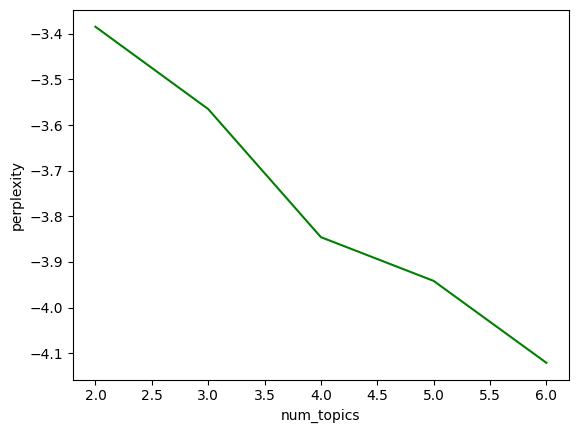

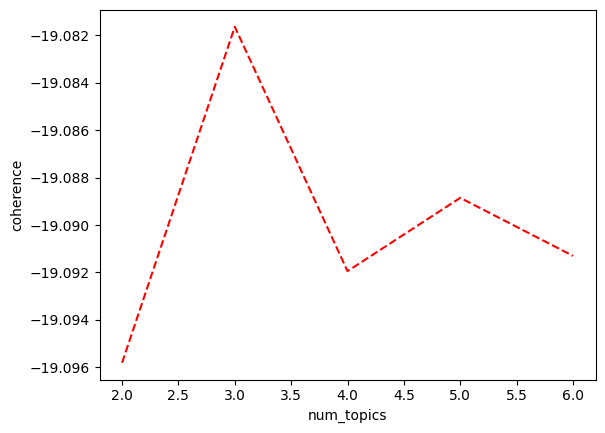

In [11]:
def show_coherence(corpus, dictionary, start=6, end=15):
    iter_num = []
    per_value = []
    coh_value = []

    for i in range(start, end + 1):
        model = LdaModel(corpus=corpus, id2word=dictionary,
                         chunksize=1000, num_topics=i,
                         random_state=7)
        iter_num.append(i)
        pv = model.log_perplexity(corpus)
        per_value.append(pv)

        cm = CoherenceModel(model=model, corpus=corpus,
                            coherence='u_mass')
        cv = cm.get_coherence()
        coh_value.append(cv)
        print(f'num_topics: {i}, perplexity: {pv:0.3f}, coherence: {cv:0.3f}')

    plt.plot(iter_num, per_value, 'g-')
    plt.xlabel("num_topics")
    plt.ylabel("perplexity")
    plt.show()

    plt.plot(iter_num, coh_value, 'r--')
    plt.xlabel("num_topics")
    plt.ylabel("coherence")
    plt.show()

show_coherence(corpus, dictionary, start=2, end=6)